**26 | Final Development Model Training, Reproducible Inference and Qualified Test Gate**

**Human Movement Intelligence | Reza Saadatyar (2026)**

This notebook implements the Stage 25 **candidate protocol** without automatically opening the reserved Test set. Its default, safe path fits one final 1D-ResNet and one Random Forest reference on all 29 Development participants, verifies Train-only preprocessing, saves both models and reloads them for reproducible inference. **No original S023/S032 source file or Test label is loaded unless the separate, explicit protocol approval gate is satisfied.** The previous descriptive inspection of these participants must always be disclosed if a qualified held-out report is later authorised.

**01. Scope, Approval Boundary and Reproducibility Setup**

The candidate procedure fixes HARTH v2.0 source revision, 100-sample time-safe pure-label windows at 50 Hz, 50-sample stride, eight original source activities, 500-window chronological cap per subject, 14,201 Development windows and 29 Development people. Final 1D-ResNet uses seed 42, 400 Adam updates, batch size 128, inverse-square-root Weighted Cross-Entropy and Development-fitted channel scaling. The fixed RF reference has 120 trees, minimum leaf size 3 and balanced-subsample weights on 30 features. Stage 25's manifest currently says `PENDING_USER_REVIEW`, so Test access is disabled.

In [1]:
%cd /content

!git clone https://github.com/RezaSaadatyar/human-movement-intelligence.git

%cd /content/human-movement-intelligence

from pathlib import Path

root = Path.cwd().resolve()

required_file = root / "code/python/src/core/data_loading.py"

print("Project root:", root)
print("Required file exists:", required_file.is_file())

/content
fatal: destination path 'human-movement-intelligence' already exists and is not an empty directory.
/content/human-movement-intelligence
Project root: /content/human-movement-intelligence
Required file exists: True


In [ ]:
# ==================== 01. Environment and Approval-Safe Protocol ====================

# 1. Locate the repository and load the already reviewed scientific settings.
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root=Path.cwd().resolve()
while not (root/"code/python/src/core/harth_final_inference.py").is_file():
    if root.parent==root:
        raise RuntimeError("Run within the HMI repository.")
    root=root.parent
sys.path.insert(0,str(root/"code/python/src"))
sys.path.insert(0,str(root/"studies/wearable_activity_recognition/src"))
from core.harth_final_inference import (
    load_final_protocol, fit_final_resnet, fit_development_scaler,
    apply_frozen_scaler, save_final_models, load_final_models,
    infer_source_windows, enforce_qualified_test_approval,
    score_qualified_heldout,
)
from harth_data import (
    HARTH_SUBJECTS, SENSOR_COLUMNS, HARTH_REVISION, ACTIVITY_NAMES,
    prepare_harth_window_cohort,
)
from core.feature_engineering import extract_signal_features
from sklearn.ensemble import RandomForestClassifier
import torch

# 2. Validate original code hashes; Test is NOT authorised by running this cell.
PROPOSAL=root/"studies/wearable_activity_recognition/experiments/stage_25_protocol_proposal_reconciled.json"
protocol=load_final_protocol(PROPOSAL,root,require_approval=False)
RESERVED_TEST={"S023","S032"}
DEVELOPMENT=sorted(set(HARTH_SUBJECTS)-RESERVED_TEST)
CLASSES=tuple(protocol["source"]["task_codes"])
ARTIFACT_DIR=root/"outputs/harth_stage26_final"
assert len(DEVELOPMENT)==29 and HARTH_REVISION==protocol["source"]["revision"]
assert len(SENSOR_COLUMNS)==6

# 3. Prefer Colab CUDA for training; record the true accelerator environment.
if not torch.cuda.is_available():
    raise RuntimeError("Enable GPU in Colab: Runtime > Change runtime type > GPU.")
DEVICE="cuda"
torch.set_float32_matmul_precision("highest")
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False
print(""+"="*70)
print("STAGE 26 | SAFE FINAL DEVELOPMENT MODEL FIT")
print("="*70)
print("GPU:",torch.cuda.get_device_name(0),"| PyTorch:",torch.__version__)
print("Source revision:",HARTH_REVISION)
print("Protocol approval status:",protocol["status"])
print("Reserved Test loaded: NO")
print("="*70)

: 

: 

**02. Original 29-Person Development Cohort and Source Integrity**

Construct the exact source-row-aligned 500-cap cohort from the official pinned recordings, applying strict time continuity and label-purity checks **before** filtering out-of-task annotations. Do not use `S023` or `S032` for fitting, feature extraction, batch-normalisation statistics, class weights or architecture decisions. The manifest's Development SHA256 is compared with the exact reconstructed sample used in Stages 23–25.

In [3]:
# ==================== 02. Development-Only Source Cohort ====================

# 1. Recreate genuine original Development source windows.
X_dev,y_dev,dev_metadata,dev_overview=prepare_harth_window_cohort(
    subjects=DEVELOPMENT,data_dir=root/"data/raw/harth_v2",
    task_classes=CLASSES,max_windows_per_subject=500,
    window_size=100,step_size=50,sampling_rate=50,
)
assert X_dev.shape==(14201,6,100)
assert len(y_dev)==len(dev_metadata)
assert set(dev_metadata["subject_id"])==set(DEVELOPMENT)
assert not(set(dev_metadata["subject_id"])&RESERVED_TEST)

# 2. Recalculate the same protocol fingerprint without importing Test data.
from core.temporal_benchmark import make_benchmark_plan
dev_plan=make_benchmark_plan(
    X_dev,y_dev,dev_metadata["subject_id"].to_numpy(),
    classes=CLASSES,n_splits=3,forbidden_subjects=RESERVED_TEST,
)
assert dev_plan["fingerprint"]==protocol["source_development_sha256"]
display(dev_overview[["subject_id","eligible_windows","sampled_windows"]])
print("Development SHA256 verified:",dev_plan["fingerprint"])
print("Actual Test source files opened: NO")

Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Downloaded 50,898,931 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 sa

/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Reje

/content/human-movement-intelligence/studies/wearable_activity_recognition/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


Development SHA256 verified: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Actual Test source files opened: NO


**03. Development-Only Channel Scaling and Source Class Weights**

The six original sensor axes must remain in the same order in every training and inference window. Channel statistics are calculated from *all final Development windows only*, not from the protected Test. Weighted Cross-Entropy receives Train-only class weights based on actual original activity codes. These parameters are not tuned using held-out observations.

In [4]:
# ==================== 03. Freeze Development Fitted Preprocessing ====================

# 1. Check the exact sensor order and Development-only fitted scaler.
scaler=fit_development_scaler(X_dev)
X_scaled=apply_frozen_scaler(X_dev,scaler)
assert X_scaled.shape==X_dev.shape and np.isfinite(X_scaled).all()
stats=pd.DataFrame({
    "channel":SENSOR_COLUMNS,
    "development_mean":scaler["mean"],
    "development_std":scaler["std"],
})
display(stats.round(6))

# 2. Describe class support; these are overlapping source-window counts.
source_counts=pd.Series(y_dev).value_counts().reindex(CLASSES,fill_value=0)
display(pd.DataFrame({
    "source_code":CLASSES,
    "activity":[ACTIVITY_NAMES[c] for c in CLASSES],
    "development_windows":source_counts.to_numpy(),
}))
assert (source_counts>0).all()

,channel,development_mean,development_std
0,back_x,-0.884657,0.423905
1,back_y,-0.020551,0.221160
2,back_z,-0.135460,0.383786
3,thigh_x,-0.654180,0.679575
4,thigh_y,-0.087987,0.405604
5,thigh_z,-0.440445,0.706797


,source_code,activity,development_windows
0,1,Walking,3591
1,2,Running,1028
2,3,Shuffling,219
3,4,Stairs ascending,192
4,5,Stairs descending,182
5,6,Standing,2227
6,7,Sitting,5599
7,8,Lying,1163


**04. Train the Final 1D-ResNet Using the Frozen 400-Update Procedure**

A newly initialised 1D-ResNet trains on the entire eligible Development cohort using seed 42, batch size 128, Adam 0.001 and inverse-square-root class weighting. It is deliberately trained for exactly 400 optimiser updates and the last-step weights are retained. There is no Validation or Test-driven checkpoint selection. The training loss trace is a diagnostic, **not** an unbiased accuracy estimate.

  Final 1D-ResNet: step 1/400 | Train loss=1.9961
  Final 1D-ResNet: step 100/400 | Train loss=0.3066
  Final 1D-ResNet: step 200/400 | Train loss=0.0779
  Final 1D-ResNet: step 300/400 | Train loss=0.0969
  Final 1D-ResNet: step 400/400 | Train loss=0.1291


,step,development_train_loss
0,1,1.996078
1,100,0.306587
2,200,0.077936
3,300,0.096873
4,400,0.129093


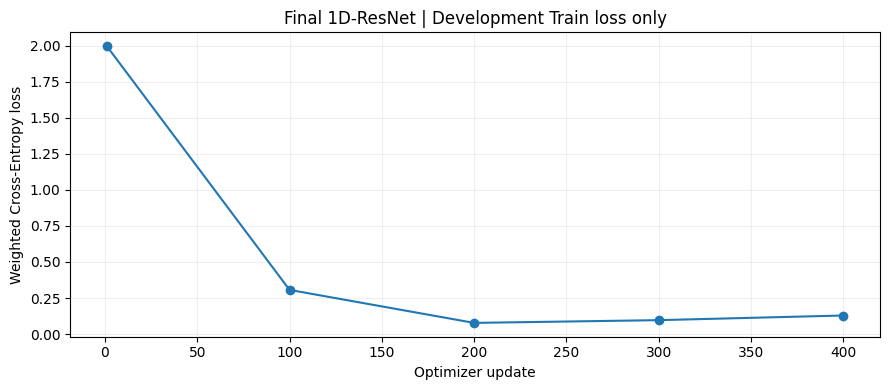

Final model fit duration (seconds): 13.83
Test data used in training: NO


In [5]:
# ==================== 04. Final Development-Only Neural Fitting ====================

# 1. Fit exactly one frozen neural model with no original Test labels.
model,trained_scaler,train_history,class_weights,train_time=fit_final_resnet(
    X_dev,y_dev,protocol,device=DEVICE
)

# 2. Verify the final training budget and visualise real Train-loss observations.
assert int(train_history["step"].iloc[-1])==400
display(train_history)
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(train_history["step"],train_history["development_train_loss"],marker="o")
ax.set(title="Final 1D-ResNet | Development Train loss only",
       xlabel="Optimizer update",ylabel="Weighted Cross-Entropy loss")
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()
print("Final model fit duration (seconds):",round(train_time,2))
print("Test data used in training: NO")

**05. Fit the Frozen Random Forest as a Classical Reference**

The Random Forest reference uses 30 deterministic features from the same eligible Development source windows. Feature extraction independently summarises each six-channel window and does not fit a Test-derived transform. The 120-tree specification is frozen from Stage 25, not selected after seeing Test performance.

In [7]:
# ==================== 05. Train the Fixed Classical Reference ====================

# 1. Extract 30 source-window features with documented and ordered names.
features=extract_signal_features(X_dev,channel_names=SENSOR_COLUMNS)
assert features.shape==(14201,30)

# 2. Fit the exact 120-tree RF specification on Development source labels.
rf=RandomForestClassifier(
    n_estimators=120,min_samples_leaf=3,
    class_weight="balanced_subsample",random_state=42,n_jobs=-1
)
rf.fit(features.to_numpy(),y_dev)
assert set(rf.classes_)==set(CLASSES)
print("RF trees:",len(rf.estimators_))
print("RF feature count:",rf.n_features_in_)
print("RF Train subjects:",len(DEVELOPMENT))
print("RF Test subjects accessed: NO")

Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
RF trees: 120
RF feature count: 30
RF Train subjects: 29
RF Test subjects accessed: NO


**06. Save Both Models, Class Mapping and Original Sensor Statistics**

A reproducible inference artefact must include more than PyTorch weights: the channel order, exact class-code map, windowing assumptions, six Development-fitted means and SDs, RF feature-column order, source fingerprint and protocol digests are saved as accompanying JSON. The original source recordings and person-level Test labels are not embedded in the artefacts. The saved RF `joblib` file must only be loaded from a trusted, locally created location.

In [8]:
# ==================== 06. Versioned Local Model Artefacts ====================

# 1. Save trusted weights, scaler, source labels and reference forest metadata.
artifact_info=save_final_models(
    model,trained_scaler,rf,list(features.columns),
    protocol,dev_plan["fingerprint"],ARTIFACT_DIR
)
display(pd.DataFrame([
    {"artifact":name,"path":path,"sha256":artifact_info["sha256"][name]}
    for name,path in artifact_info.items() if name!="sha256"
]))
print("Model artefacts stored locally:",ARTIFACT_DIR)
print("Artefacts are ignored by Git and should not be committed.")

,artifact,path,sha256
0,resnet,/content/human-movement-intelligence/outputs/h...,b7a579c60cc6692566939b1250e1d8683653bd879ee92e...
1,reference,/content/human-movement-intelligence/outputs/h...,658a5ea1e2195b0c3631629649a47f89ed9bced1eea8f7...
2,config,/content/human-movement-intelligence/outputs/h...,f4d02dc5f9e2e9a9387de47690d7c342f58343c929a68c...


Model artefacts stored locally: /content/human-movement-intelligence/outputs/harth_stage26_final
Artefacts are ignored by Git and should not be committed.


**07. Reload Exact Artefacts and Verify Prediction Consistency**

Test the complete reproducible inference pathway on Development source windows *only*. This round-trip check catches missing weights, incompatible input shapes, incorrect class labels, channel-order errors and forgotten normalisation statistics. Agreement with in-memory predictions is an engineering requirement, not evidence that the model will generalise to new participants.

In [9]:
# ==================== 07. Development Inference Round-Trip Check ====================

# 1. Load saved models and preprocessing from the newly written trusted directory.
loaded_model,loaded_rf,config=load_final_models(ARTIFACT_DIR,device="cpu")
N_CHECK=24
unseen_style_windows=X_dev[:N_CHECK]
reloaded_nn,reloaded_rf=infer_source_windows(
    unseen_style_windows,loaded_model,loaded_rf,config,device="cpu"
)

# 2. Verify original class codes and compare RF reload to the original fitted model.
assert len(reloaded_nn)==len(reloaded_rf)==N_CHECK
assert set(reloaded_nn).issubset(CLASSES)
assert set(reloaded_rf).issubset(CLASSES)
direct_rf=rf.predict(
    features.iloc[:N_CHECK].to_numpy()
)
np.testing.assert_array_equal(reloaded_rf,direct_rf)
display(pd.DataFrame({
    "true_dev_code":y_dev[:N_CHECK],
    "reloaded_resnet_prediction":reloaded_nn,
    "reloaded_rf_prediction":reloaded_rf,
}))
print("Saved neural and classical inference: PASSED")
print("Independent Test model performance assessed: NO")

Input windows: (24, 6, 100)
Feature matrix: (24, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length


,true_dev_code,reloaded_resnet_prediction,reloaded_rf_prediction
0,1,6,6
1,6,6,6
2,6,6,6
3,6,6,6
4,6,6,6
5,6,6,6
6,6,6,6
7,6,6,6
8,6,6,6
9,6,6,6


Saved neural and classical inference: PASSED
Independent Test model performance assessed: NO


**08. Security and Test-Gate Review (Non-Executing by Default)**

**No Test source access occurs in this notebook by default.** The existing Stage 25 JSON still has `PENDING_USER_REVIEW`. To authorise Test evaluation in a later review, the user must explicitly confirm the source cohort, 500-window sampling policy for both original reserved participants, eight-class metrics, original descriptive-inspection limitation, and the decision to report one frozen primary model plus RF reference. A passing Development training Quality Gate is not equivalent to Test authorisation.

In [10]:
# ==================== 08. Demonstrate Test Gate WITHOUT Source Access ====================

# 1. Check the current approval state and explain why Test is not accessible.
print("Protocol status:",protocol["status"])
print("Qualified Test requested in this notebook: NO")
if protocol["status"]!="APPROVED":
    print("Qualified Test gate: BLOCKED pending explicit user review.")
else:
    print("Qualified Test gate: approval recorded; separate confirmation still required.")

# 2. Do not load, download, enumerate or score either reserved recording.
assert RESERVED_TEST=={"S023","S032"}
print("S023 and S032 recordings read in this notebook: NO")

Protocol status: PENDING_USER_REVIEW
Qualified Test requested in this notebook: NO
Qualified Test gate: BLOCKED pending explicit user review.
S023 and S032 recordings read in this notebook: NO


**09. Define the Qualified Held-Out Report, Without Running It**

After approval, Stage 26 may be extended to a separately gated Test execution using the same source-window preprocessing, exactly 500 eligible post-windowing samples per reserved person, and existing frozen models. Both Test subjects must be reported separately, along with fixed-eight-class Macro F1, Balanced Accuracy, overall Accuracy, class precision/recall/F1/support and confusion matrices. No Test-driven changes or selecting whichever model scores higher are permitted. Previously inspecting the reserved recordings and their same-study provenance preclude calling this an independent blind external benchmark.

In [11]:
# ==================== 09. Explicit Qualified Test Reporting Contract ====================

# 1. Show planned metrics only, not hypothetical Test scores.
report_plan=pd.DataFrame([
    {"evaluation":"Primary metric","requirement":"Fixed eight-class Macro F1"},
    {"evaluation":"Secondary metrics","requirement":"Balanced accuracy and overall accuracy"},
    {"evaluation":"Per-class diagnostics","requirement":"Precision, recall, F1, actual support"},
    {"evaluation":"Independent people","requirement":"S023 and S032 reported separately"},
    {"evaluation":"Model comparison","requirement":"Frozen ResNet and predeclared RF reference"},
    {"evaluation":"Forbidden operations","requirement":"No Test-driven refitting, model choice or hyperparameter search"},
    {"evaluation":"Scientific limitation","requirement":"Originally descriptively inspected; same-study, not external"},
])
display(report_plan)
print("Test metrics created by this stage: NONE")

,evaluation,requirement
0,Primary metric,Fixed eight-class Macro F1
1,Secondary metrics,Balanced accuracy and overall accuracy
2,Per-class diagnostics,"Precision, recall, F1, actual support"
3,Independent people,S023 and S032 reported separately
4,Model comparison,Frozen ResNet and predeclared RF reference
5,Forbidden operations,"No Test-driven refitting, model choice or hype..."
6,Scientific limitation,Originally descriptively inspected; same-study...


Test metrics created by this stage: NONE


**10. Reproducibility Summary and Final Development Quality Gate**

A passing gate here verifies that both **final Development-fitted** models exist, their frozen metadata are present and reloadable, source-window/label correspondence remains intact and no protected Test participant was loaded. This does not verify a reserved-Test generalisation claim. Approval remains a separate human decision; Stage 27's report must distinguish trained artefact readiness from externally validated performance.

In [12]:
# ==================== 10. Final Training and Inference Quality Gate ====================

# 1. Confirm exact source cohort, frozen controls and trained model artefacts.
assert X_dev.shape==(14201,6,100)
assert set(dev_metadata["subject_id"])==set(DEVELOPMENT)
assert not(set(dev_metadata["subject_id"])&RESERVED_TEST)
assert protocol["primary_model"]["optimizer_steps"]==400
assert train_history["step"].iloc[-1]==400
assert len(class_weights)==8 and np.isfinite(class_weights).all()
assert all(Path(path).is_file() for name,path in artifact_info.items() if name!="sha256")

# 2. Verify complete raw-window inference with Development-fitted statistics.
assert config["source_codes"]==list(CLASSES)
assert config["sensor_columns"]==SENSOR_COLUMNS
assert config["preprocessing_fit_scope"]=="Development only"
assert not config["test_fitted_values"]
np.testing.assert_array_equal(reloaded_rf,direct_rf)

# 3. Report clearly which objectives have, and have NOT, been achieved.
print(""+"="*70)
print("STAGE 26 | FROZEN DEVELOPMENT FIT AND INFERENCE ARTEFACTS")
print("="*70)
print("Frozen 29-person Development cohort: VERIFIED")
print("Primary 1D-ResNet trained: YES, 400 fixed updates")
print("Fixed Random Forest trained: YES, 120 trees")
print("Train-only scaler, class map and channel order: SAVED")
print("Trusted artifact reloading/inference: PASSED")
print("Original S023/S032 Test accessed: NO")
print("-"*70)
print("Stage 26 Development training/inference quality gate: PASSED")
print("Protocol approval status:",protocol["status"])
print("Qualified Test evaluation performed: NO")
print("Next: explicit qualified-Test approval and separate gated scoring")
print("="*70)

STAGE 26 | FROZEN DEVELOPMENT FIT AND INFERENCE ARTEFACTS
Frozen 29-person Development cohort: VERIFIED
Primary 1D-ResNet trained: YES, 400 fixed updates
Fixed Random Forest trained: YES, 120 trees
Train-only scaler, class map and channel order: SAVED
Trusted artifact reloading/inference: PASSED
Original S023/S032 Test accessed: NO
----------------------------------------------------------------------
Stage 26 Development training/inference quality gate: PASSED
Protocol approval status: PENDING_USER_REVIEW
Qualified Test evaluation performed: NO
Next: explicit qualified-Test approval and separate gated scoring


**11. Authorised Qualified Held-Out Source Evaluation**

This section is run only after the author's explicit approval of the unchanged Stage 25 protocol. Both S023 and S032 were examined descriptively in exploratory stages and are *not* historically unseen or an external cohort. We use exactly the frozen 500-cap, 100-sample, stride-50, eight-code segmentation and both previously trained Development models. No Test observation influences the scaler, model parameters, checkpoint, thresholds or model choice.

The approved versioned manifest records the user's decision without overwriting either historical Stage 25 candidate. The second exact gate is deliberately checked in this cell. Existing trusted Development-fitted artefacts from Sections 01–10 are required. **Do not execute this section to inspect/test different model settings, and do not repeat this evaluation for model selection.**

In [13]:
# ==================== 11. Approved One-Time Qualified Test Inference ====================

# 1. Confirm the separately approved protocol without altering existing manifests.
import hashlib
import json
from core.harth_final_inference import (
    sha256_file, load_final_protocol, enforce_qualified_test_approval,
    load_final_models, infer_source_windows, TEST_CONFIRMATION,
)
from core.harth_qualified_test_report import (
    validate_final_test_inputs, summarise_qualified_heldout,
    SOURCE_CLASSES, RESERVED_PEOPLE, FINAL_MODELS,
)

approved_path = root / "studies/wearable_activity_recognition/experiments/stage_25_protocol_approved_qualified_test.json"
approved = load_final_protocol(approved_path, root, require_approval=True)
assert approved["approval_record"]["scope"].startswith("One-time qualified")
assert approved["source_development_sha256"] == protocol["source_development_sha256"]
assert approved["primary_model"] == protocol["primary_model"]
assert approved["reference_model"] == protocol["reference_model"]
assert approved["source"] == protocol["source"]
assert approved["evaluation"] == protocol["evaluation"]
assert approved["module_sha256"] == protocol["module_sha256"]
assert enforce_qualified_test_approval(approved, TEST_CONFIRMATION)

# 2. Reload only the previously saved, locally trusted Development artefacts.
expected_artifacts = ["resnet_state_dict.pt", "random_forest.joblib", "inference_config.json"]
for filename in expected_artifacts:
    assert (ARTIFACT_DIR / filename).is_file(), (
        f"Missing Development artefact {filename}; recover trusted files or "
        "rerun the unchanged Development-only Sections 01–10."
    )
assert approved["source_development_sha256"] == dev_plan["fingerprint"]
assert config["development_cohort_sha256"] == approved["source_development_sha256"]
assert config["sensor_columns"] == SENSOR_COLUMNS
assert config["source_codes"] == list(SOURCE_CLASSES)
assert config["preprocessing_fit_scope"] == "Development only"
assert not config["test_fitted_values"]
assert all(sha256_file(artifact_info[key]) == artifact_info["sha256"][key]
           for key in ("resnet", "reference", "config"))
frozen_nn, frozen_rf, frozen_config = load_final_models(ARTIFACT_DIR, device="cpu")
assert frozen_config == config
print("Approved protocol and trusted Development artefacts: VERIFIED")

# 3. Exactly once, construct reserved original HARTH recordings with frozen windowing.
X_test, y_test, test_metadata, test_overview = prepare_harth_window_cohort(
    subjects=list(RESERVED_PEOPLE),
    data_dir=root / "data/raw/harth_v2",
    task_classes=tuple(SOURCE_CLASSES),
    max_windows_per_subject=approved["source"]["test_cap_per_person"],
    window_size=approved["source"]["window_size"],
    step_size=approved["source"]["step_size"],
    sampling_rate=approved["source"]["sampling_rate_hz"],
)
assert X_test.ndim == 3 and X_test.shape[1:] == (6, 100)
assert len(y_test) == len(test_metadata) and len(y_test) <= 1000
assert set(test_metadata["subject_id"]) == set(RESERVED_PEOPLE)
assert not set(test_metadata["subject_id"]).intersection(DEVELOPMENT)
assert all(test_overview["sampled_windows"].between(1, 500))
assert np.isfinite(X_test).all()

# 4. Predict using already-frozen fitted networks, without Test fitting or tuning.
pred_resnet, pred_rf = infer_source_windows(
    X_test, frozen_nn, frozen_rf, frozen_config, device="cpu"
)
predictions = {
    "1D-ResNet Weighted CE": pred_resnet,
    "Random Forest": pred_rf,
}
y_checked, subject_checked, predictions, code_order = validate_final_test_inputs(
    y_test, test_metadata["subject_id"].to_numpy(), predictions
)
display(test_overview[["subject_id", "eligible_windows", "sampled_windows"]])
print("Qualified Test windows:", len(y_checked))
print("Models evaluated: both frozen Development models")
print("Test-driven training, calibration, threshold tuning: NONE")


ModuleNotFoundError: No module named 'core.harth_qualified_test_report'

**12. Frozen-Model Test Metrics, Per-Person/Class Reporting and Visualisation**

Report all eight predeclared class codes with their **actual** source support, including any absent class. Fixed-eight-class Macro F1 and observed-class balanced accuracy must not be conflated. Every participant is shown separately, alongside pooled overlapping-window descriptive scores, full source-code confusion matrices and labelled support. The same original Test sample indices are used for both models.

Results are descriptive given two correlated, previously inspected participants. The predeclared model remains 1D-ResNet Weighted CE regardless of the comparative result.

In [ ]:
# ==================== 12. Frozen Qualified Test Results ====================

# 1. Compute only previously declared metrics from frozen predictions.
report = summarise_qualified_heldout(
    y_checked, subject_checked, predictions, ACTIVITY_NAMES, SOURCE_CLASSES
)
print("FINAL QUALIFIED SAME-STUDY HELD-OUT EVALUATION")
print("Primary model selected on Development: 1D-ResNet Weighted CE")
print("The Test comparison DOES NOT select a replacement.")
display(report["summary"].round(4))
display(report["per_subject"].round(4))
display(report["per_class"].round(4))

# 2. Plot both original eight-by-eight confusion matrices.
import matplotlib.pyplot as plt
for model_name in FINAL_MODELS:
    cm = report["confusion"][model_name]
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_xticks(range(8), [str(code) for code in SOURCE_CLASSES])
    ax.set_yticks(range(8), [str(code) for code in SOURCE_CLASSES])
    ax.set_xlabel("Predicted original source activity code")
    ax.set_ylabel("True original source activity code")
    ax.set_title(f"Qualified held-out count confusion matrix | {model_name}")
    for row in range(8):
        for column in range(8):
            ax.text(column, row, str(int(cm[row, column])),
                    ha="center", va="center", fontsize=8,
                    color="white" if cm[row, column] > 0.5 * cm.max() else "black")
    fig.colorbar(image, ax=ax, label="Overlapping-window count")
    fig.tight_layout()
    plt.show()

# 3. Display class recall and actual support without hiding weak classes.
for model_name in FINAL_MODELS:
    subset = report["per_class"].query("model == @model_name").copy()
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(subset["activity"], subset["recall"])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Recall (0–1)")
    ax.set_title(f"Qualified held-out per-class recall | {model_name}")
    ax.tick_params(axis="x", rotation=40)
    for idx, row in enumerate(subset.itertuples()):
        ax.text(idx, min(row.recall + 0.02, 0.98), f"n={row.support}",
                ha="center", va="bottom", fontsize=8)
    fig.tight_layout()
    plt.show()


**13. Source-Grounded Final Quality Gate and Reproducibility Evidence**

The final gate establishes **only** that one approved held-out evaluation used both original reserved people, the same selected source rows, the original eight activity codes and immutable Development-fitted model artefacts. It does not prove independence, statistical significance, deployment readiness or external transfer. Local reports are ignored by Git and should be retained separately if Colab is reset. The executed notebook may be committed as the provenance record only after manual inspection of its genuine outputs.

**Do not rerun Test scoring for hyperparameter or architecture choices.** Stage 27 reports these findings, including failure modes, with the historical inspection limitation.

In [ ]:
# ==================== 13. Final Qualified Held-Out Quality Gate ====================

# 1. Revalidate saved artefact bytes and frozen original source/candidate evidence.
assert approved["status"] == "APPROVED"
assert set(subject_checked) == set(RESERVED_PEOPLE)
assert len(y_checked) == len(predictions["1D-ResNet Weighted CE"])
assert len(y_checked) == len(predictions["Random Forest"])
assert report["summary"]["model"].tolist() == list(FINAL_MODELS)
assert len(report["per_class"]) == 16 and len(report["per_subject"]) == 4
assert all(report["per_class"].groupby("model")["support"].sum() == len(y_checked))
assert all(int(cm.sum()) == len(y_checked) for cm in report["confusion"].values())
assert all(sha256_file(artifact_info[key]) == artifact_info["sha256"][key]
           for key in ("resnet", "reference", "config"))

# 2. Export reproducibility evidence and identical per-window model predictions.
import hashlib
from pathlib import Path
result_dir = root / "outputs/harth_stage26_qualified_test"
result_dir.mkdir(parents=True, exist_ok=True)
report["summary"].to_csv(result_dir / "qualified_model_summary.csv", index=False)
report["per_subject"].to_csv(result_dir / "qualified_per_subject.csv", index=False)
report["per_class"].to_csv(result_dir / "qualified_per_class.csv", index=False)
for model_name in FINAL_MODELS:
    safe_name = "resnet" if model_name.startswith("1D-") else "random_forest"
    pd.DataFrame(report["confusion"][model_name]).to_csv(
        result_dir / f"{safe_name}_confusion_counts.csv", index=False, header=False
    )
pd.DataFrame({
    "subject_id": subject_checked,
    "true_source_code": y_checked,
    "resnet_predicted_source_code": predictions["1D-ResNet Weighted CE"],
    "random_forest_predicted_source_code": predictions["Random Forest"],
}).to_csv(result_dir / "aligned_frozen_predictions.csv", index=False)
provenance = {
    "scientific_status": "qualified same-study held-out; historically inspected; not blind/external",
    "source_revision": approved["source"]["revision"],
    "development_cohort_sha256": approved["source_development_sha256"],
    "approved_manifest_sha256": sha256_file(approved_path),
    "artifact_sha256": {key: sha256_file(artifact_info[key])
                        for key in ("resnet", "reference", "config")},
    "models": list(FINAL_MODELS),
    "test_people": list(RESERVED_PEOPLE),
    "test_windows": len(y_checked),
    "test_tuning_or_retraining": False,
    "fixed_macro_f1_denominator": list(SOURCE_CLASSES),
    "balanced_accuracy_denominator": "Observed true classes (sklearn)",
}
(result_dir / "qualified_test_provenance.json").write_text(
    json.dumps(provenance, indent=2) + "\n", encoding="utf-8"
)
print("=" * 76)
print("STAGE 26 | QUALIFIED HELD-OUT EVALUATION: PASSED")
print("=" * 76)
print("Frozen original Test subjects:", ", ".join(RESERVED_PEOPLE))
print("Reported windows:", len(y_checked))
print("Both locked models evaluated on identical source windows: YES")
print("Eight-class Macro F1, per-class and per-person metrics: SAVED")
print("Artefact SHA256 verified after inference: YES")
print("Test-driven model selection/tuning: NO")
print("External validation or independent blind study: NO")
print("Results stored locally:", result_dir)
print("Next: inspect real results, save executed notebook, then Stage 27.")
print("=" * 76)
